# E-commerce Sales Data Analysis (End-to-End)
**Libraries used:** pandas, numpy, matplotlib, seaborn

**Steps:** 1. Data Understanding → 2. Column Info → 3. Data Types → 4. Data Cleaning → 5. Analysis → 6. Visualization → 7. Business Insights

> Note: this dataset is about user behaviour on an e-commerce website. It has **no `order_date`, price or revenue column**,
> so `purchase` (1 = bought, 0 = not bought), `cart_items` and `previous_purchases` are used as the sales measures.
> The date and negative-value checks are still written, so the same code works on any sales file.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
# Load the dataset
df = pd.read_csv("ecommerce_user_behavior_8000.csv")
df.head()

,user_id,age,gender,device_type,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,avg_session_time,bounce_rate,purchase
0,1.0,56.0,Female,Desktop,12.90,8.0,13.0,1.0,1.0,NaN,0.0,6.97,28.18,1.0
1,2.0,46.0,Male,Mobile,15.63,9.0,4.0,6.0,1.0,1.0,1.0,19.17,86.73,1.0
2,3.0,32.0,Female,NaN,11.64,12.0,11.0,0.0,0.0,0.0,1.0,8.87,83.09,1.0
3,4.0,25.0,Female,Mobile,22.71,5.0,10.0,1.0,0.0,0.0,1.0,NaN,79.03,1.0
4,5.0,38.0,Female,Mobile,26.35,9.0,12.0,4.0,1.0,0.0,0.0,18.15,55.35,1.0


## 1. Data Understanding

In [3]:
# Number of rows and columns
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

Rows    : 8000
Columns : 14


In [4]:
# Last 5 rows
df.tail()

,user_id,age,gender,device_type,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,avg_session_time,bounce_rate,purchase
7995,7996.0,48.0,Female,Tablet,2.67,10.0,6.0,0.0,1.0,0.0,1.0,3.01,82.44,1.0
7996,7997.0,54.0,Male,Mobile,18.94,13.0,11.0,4.0,1.0,1.0,1.0,27.48,10.06,1.0
7997,7998.0,54.0,Female,Desktop,24.08,8.0,13.0,1.0,0.0,0.0,1.0,27.57,21.34,1.0
7998,7999.0,32.0,Female,Mobile,10.85,13.0,12.0,8.0,1.0,1.0,0.0,5.78,2.03,1.0
7999,8000.0,46.0,Female,Mobile,12.23,2.0,9.0,2.0,0.0,1.0,1.0,8.28,15.67,1.0


In [5]:
# Summary statistics of numeric columns
df.describe()

,user_id,age,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,avg_session_time,bounce_rate,purchase
count,7840.000000,7840.000000,7840.000000,7840.000000,7840.000000,7840.000000,7840.000000,7840.000000,7840.000000,7840.000000,7840.000000,7840.000000
mean,4003.135077,38.595791,15.714673,9.970026,6.964158,4.530230,0.502551,0.502296,0.509439,15.794999,49.924402,0.998342
std,2307.898984,12.033928,8.362764,5.425485,4.281117,2.865814,0.500025,0.500027,0.499943,9.864556,29.137449,0.040689
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.570000,0.010000,0.000000
25%,2011.750000,28.000000,8.520000,5.000000,3.000000,2.000000,0.000000,0.000000,0.000000,7.750000,24.677500,1.000000
50%,3998.000000,39.000000,15.740000,10.000000,7.000000,5.000000,1.000000,1.000000,1.000000,14.300000,49.500000,1.000000
75%,6001.250000,49.000000,22.880000,15.000000,11.000000,7.000000,1.000000,1.000000,1.000000,22.392500,75.990000,1.000000
max,8000.000000,59.000000,30.000000,19.000000,14.000000,9.000000,1.000000,1.000000,1.000000,44.750000,99.970000,1.000000


## 2. Column Info

| Column | Meaning |
|---|---|
| user_id | Unique ID of the user |
| age | Age of the user |
| gender | Male / Female |
| device_type | Mobile / Desktop / Tablet |
| time_on_site | Minutes spent on the website |
| pages_viewed | Number of pages seen |
| previous_purchases | Number of past orders |
| cart_items | Items added to cart |
| discount_seen | 1 = saw a discount, 0 = no |
| ad_clicked | 1 = clicked an ad, 0 = no |
| returning_user | 1 = old user, 0 = new user |
| avg_session_time | Average session time (minutes) |
| bounce_rate | % chance of leaving after one page |
| purchase | **Target** – 1 = bought, 0 = not bought |

In [6]:
# Column names
print(df.columns.tolist())

['user_id', 'age', 'gender', 'device_type', 'time_on_site', 'pages_viewed', 'previous_purchases', 'cart_items', 'discount_seen', 'ad_clicked', 'returning_user', 'avg_session_time', 'bounce_rate', 'purchase']


In [7]:
# Column info: data type + non-null count
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   user_id             7840 non-null   float64
 1   age                 7840 non-null   float64
 2   gender              7840 non-null   str    
 3   device_type         7840 non-null   str    
 4   time_on_site        7840 non-null   float64
 5   pages_viewed        7840 non-null   float64
 6   previous_purchases  7840 non-null   float64
 7   cart_items          7840 non-null   float64
 8   discount_seen       7840 non-null   float64
 9   ad_clicked          7840 non-null   float64
 10  returning_user      7840 non-null   float64
 11  avg_session_time    7840 non-null   float64
 12  bounce_rate         7840 non-null   float64
 13  purchase            7840 non-null   float64
dtypes: float64(12), str(2)
memory usage: 875.1 KB


## 3. Data Types

In [8]:
# Data type of each column
df.dtypes

user_id               float64
age                   float64
gender                    str
device_type               str
time_on_site          float64
pages_viewed          float64
previous_purchases    float64
cart_items            float64
discount_seen         float64
ad_clicked            float64
returning_user        float64
avg_session_time      float64
bounce_rate           float64
purchase              float64
dtype: object

In [9]:
# Separate numeric and text (categorical) columns
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns    :", num_cols)
print("Categorical columns:", cat_cols)

Numeric columns    : ['user_id', 'age', 'time_on_site', 'pages_viewed', 'previous_purchases', 'cart_items', 'discount_seen', 'ad_clicked', 'returning_user', 'avg_session_time', 'bounce_rate', 'purchase']
Categorical columns: ['gender', 'device_type']


In [10]:
# Unique values in categorical columns
for col in cat_cols:
    print(col, "->", df[col].unique())

gender -> <StringArray>
['Female', 'Male', nan]
Length: 3, dtype: str
device_type -> <StringArray>
['Desktop', 'Mobile', nan, 'Tablet']
Length: 4, dtype: str


## 4. Data Cleaning

### 4.1 Check missing values

In [11]:
# Count and % of missing values in every column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

pd.DataFrame({"missing_count": missing, "missing_%": missing_pct})

,missing_count,missing_%
user_id,160,2.0
age,160,2.0
gender,160,2.0
device_type,160,2.0
time_on_site,160,2.0
pages_viewed,160,2.0
previous_purchases,160,2.0
cart_items,160,2.0
discount_seen,160,2.0
ad_clicked,160,2.0


In [12]:
# How many rows have at least one missing value?
print("Rows with any missing value:", df.isnull().any(axis=1).sum())

Rows with any missing value: 1981


Every column has 160 missing values (2%), but they are in different rows, so about 25% of rows have at least one gap.
Dropping all of them would lose too much data. So:
- Drop rows where **user_id** or **purchase** is missing (we cannot identify the user / we don't know the result).
- Fill other **numeric** columns with the **median**.
- Fill **categorical** and **0/1** columns with the **mode** (most common value).

In [13]:
# Step 1: drop rows where user_id or purchase is missing
df = df.dropna(subset=["user_id", "purchase"])

# Step 2: fill numeric columns with median
median_cols = ["age", "time_on_site", "pages_viewed", "previous_purchases",
               "cart_items", "avg_session_time", "bounce_rate"]
for col in median_cols:
    df[col] = df[col].fillna(df[col].median())

# Step 3: fill categorical and 0/1 columns with mode
mode_cols = ["gender", "device_type", "discount_seen", "ad_clicked", "returning_user"]
for col in mode_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values left:", df.isnull().sum().sum())
print("Rows now:", len(df))

Missing values left: 0
Rows now: 7686


### 4.2 Check duplicates

In [14]:
# Full duplicate rows
print("Duplicate rows    :", df.duplicated().sum())

# Duplicate user IDs
print("Duplicate user_id :", df["user_id"].duplicated().sum())

Duplicate rows    : 0
Duplicate user_id : 0


In [15]:
# Remove duplicates (if any)
df = df.drop_duplicates()
df = df.drop_duplicates(subset="user_id")
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 7686


### 4.3 Convert order_date

In [16]:
# Convert order_date to datetime (only if the column exists)
if "order_date" in df.columns:
    df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
    df["year"] = df["order_date"].dt.year
    df["month"] = df["order_date"].dt.month
    print("order_date converted to datetime")
else:
    print("No 'order_date' column in this dataset - nothing to convert")

No 'order_date' column in this dataset - nothing to convert


### 4.4 Check negative values

In [17]:
# Count negative values in each numeric column
negative = (df[num_cols] < 0).sum()
negative

user_id               0
age                   0
time_on_site          0
pages_viewed          0
previous_purchases    0
cart_items            0
discount_seen         0
ad_clicked            0
returning_user        0
avg_session_time      0
bounce_rate           0
purchase              0
dtype: int64

In [18]:
# Remove rows with negative values (if any) - values like age, cart_items can't be negative
df = df[(df[num_cols] >= 0).all(axis=1)]
print("Rows after removing negatives:", len(df))

Rows after removing negatives: 7686


### 4.5 Fix data types

In [19]:
# These columns hold whole numbers, so change float -> int
int_cols = ["user_id", "age", "pages_viewed", "previous_purchases", "cart_items",
            "discount_seen", "ad_clicked", "returning_user", "purchase"]
df[int_cols] = df[int_cols].astype(int)

df.dtypes

user_id                 int64
age                     int64
gender                    str
device_type               str
time_on_site          float64
pages_viewed            int64
previous_purchases      int64
cart_items              int64
discount_seen           int64
ad_clicked              int64
returning_user          int64
avg_session_time      float64
bounce_rate           float64
purchase                int64
dtype: object

### 4.6 Check outliers (IQR method)

In [20]:
# Count outliers in each numeric column using IQR
for col in ["age", "time_on_site", "pages_viewed", "cart_items", "avg_session_time", "bounce_rate"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, "->", outliers, "outliers")

age -> 0 outliers
time_on_site -> 0 outliers
pages_viewed -> 0 outliers
cart_items -> 0 outliers
avg_session_time -> 7 outliers
bounce_rate -> 0 outliers


Only a few outliers in `avg_session_time` and they are realistic (long sessions), so we keep them.

In [21]:
# Add a helper column: age group
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 60],
                         labels=["18-25", "26-35", "36-45", "46-59"])

# Save the clean dataset
df.to_csv("ecommerce_user_behavior_clean.csv", index=False)
print("Clean data shape:", df.shape)
df.head()

Clean data shape: (7686, 15)


,user_id,age,gender,device_type,time_on_site,pages_viewed,previous_purchases,cart_items,discount_seen,ad_clicked,returning_user,avg_session_time,bounce_rate,purchase,age_group
0,1,56,Female,Desktop,12.90,8,13,1,1,1,0,6.97,28.18,1,46-59
1,2,46,Male,Mobile,15.63,9,4,6,1,1,1,19.17,86.73,1,46-59
2,3,32,Female,Mobile,11.64,12,11,0,0,0,1,8.87,83.09,1,26-35
3,4,25,Female,Mobile,22.71,5,10,1,0,0,1,14.30,79.03,1,18-25
4,5,38,Female,Mobile,26.35,9,12,4,1,0,0,18.15,55.35,1,36-45


## 5. Data Analysis

In [22]:
# Key numbers (KPIs)
total_users = len(df)
buyers = df["purchase"].sum()
conversion_rate = buyers / total_users * 100

print("Total users          :", total_users)
print("Total buyers         :", buyers)
print("Non-buyers           :", total_users - buyers)
print("Conversion rate      :", round(conversion_rate, 2), "%")
print("Total cart items     :", df["cart_items"].sum())
print("Avg cart items/user  :", round(df["cart_items"].mean(), 2))
print("Avg time on site     :", round(df["time_on_site"].mean(), 2), "min")
print("Avg bounce rate      :", round(df["bounce_rate"].mean(), 2), "%")

Total users          : 7686
Total buyers         : 7674
Non-buyers           : 12
Conversion rate      : 99.84 %
Total cart items     : 34865
Avg cart items/user  : 4.54
Avg time on site     : 15.71 min
Avg bounce rate      : 49.89 %


In [23]:
# Users by device
df["device_type"].value_counts()

device_type
Mobile     4651
Desktop    2279
Tablet      756
Name: count, dtype: int64

In [24]:
# Share of users by device (%)
(df["device_type"].value_counts(normalize=True) * 100).round(1)

device_type
Mobile     60.5
Desktop    29.7
Tablet      9.8
Name: proportion, dtype: float64

In [25]:
# Cart items and buyers by device
df.groupby("device_type").agg(users=("user_id", "count"),
                              total_cart_items=("cart_items", "sum"),
                              avg_cart_items=("cart_items", "mean"),
                              buyers=("purchase", "sum")).round(2)

,users,total_cart_items,avg_cart_items,buyers
device_type,,,,
Desktop,2279,10296,4.52,2277
Mobile,4651,21185,4.55,4642
Tablet,756,3384,4.48,755


In [26]:
# Gender-wise analysis
df.groupby("gender")[["cart_items", "previous_purchases", "time_on_site", "bounce_rate"]].mean().round(2)

,cart_items,previous_purchases,time_on_site,bounce_rate
gender,,,,
Female,4.59,6.89,15.73,50.3
Male,4.49,7.03,15.70,49.5


In [27]:
# Age-group analysis
df.groupby("age_group", observed=True).agg(users=("user_id", "count"),
                                            total_cart_items=("cart_items", "sum"),
                                            avg_cart_items=("cart_items", "mean")).round(2)

,users,total_cart_items,avg_cart_items
age_group,,,
18-25,1402,6372,4.54
26-35,1771,8021,4.53
36-45,2010,9115,4.53
46-59,2503,11357,4.54


In [28]:
# Buyers vs non-buyers - what is different?
df.groupby("purchase")[["time_on_site", "pages_viewed", "cart_items",
                        "previous_purchases", "bounce_rate"]].mean().round(2)

,time_on_site,pages_viewed,cart_items,previous_purchases,bounce_rate
purchase,,,,,
0,3.63,6.75,0.50,1.25,86.08
1,15.73,9.98,4.54,6.97,49.83


In [29]:
# Does discount / ad / returning user change behaviour?
for col in ["discount_seen", "ad_clicked", "returning_user"]:
    print(df.groupby(col)[["cart_items", "time_on_site", "bounce_rate"]].mean().round(2), "\n")

               cart_items  time_on_site  bounce_rate
discount_seen                                       
0                    4.56         15.80        50.04
1                    4.51         15.63        49.74 

            cart_items  time_on_site  bounce_rate
ad_clicked                                       
0                 4.55         15.80        49.91
1                 4.52         15.63        49.86 

                cart_items  time_on_site  bounce_rate
returning_user                                       
0                     4.52         15.54        50.26
1                     4.55         15.87        49.54 



In [30]:
# Correlation between numeric columns
corr = df[["age", "time_on_site", "pages_viewed", "previous_purchases", "cart_items",
           "avg_session_time", "bounce_rate", "purchase"]].corr().round(2)
corr

,age,time_on_site,pages_viewed,previous_purchases,cart_items,avg_session_time,bounce_rate,purchase
age,1.00,0.01,-0.01,-0.01,0.00,-0.00,-0.00,0.00
time_on_site,0.01,1.00,-0.03,-0.00,-0.01,0.84,0.01,0.06
pages_viewed,-0.01,-0.03,1.00,-0.02,-0.00,-0.02,-0.01,0.02
previous_purchases,-0.01,-0.00,-0.02,1.00,-0.01,-0.00,-0.01,0.05
cart_items,0.00,-0.01,-0.00,-0.01,1.00,-0.00,0.00,0.06
avg_session_time,-0.00,0.84,-0.02,-0.00,-0.00,1.00,0.01,0.05
bounce_rate,-0.00,0.01,-0.01,-0.01,0.00,0.01,1.00,-0.05
purchase,0.00,0.06,0.02,0.05,0.06,0.05,-0.05,1.00


## 6. Data Visualization

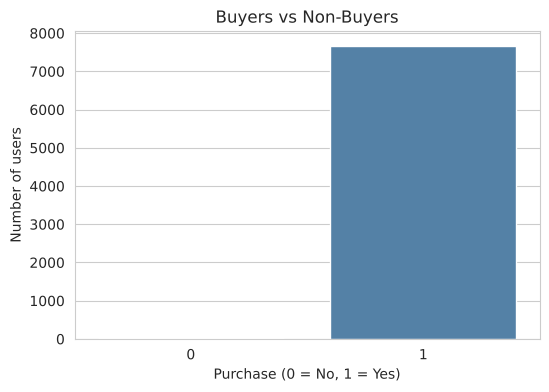

In [31]:
# 1. Purchase count (buyers vs non-buyers)
plt.figure(figsize=(6, 4))
sns.countplot(x="purchase", data=df, color="steelblue")
plt.title("Buyers vs Non-Buyers")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Number of users")
plt.show()

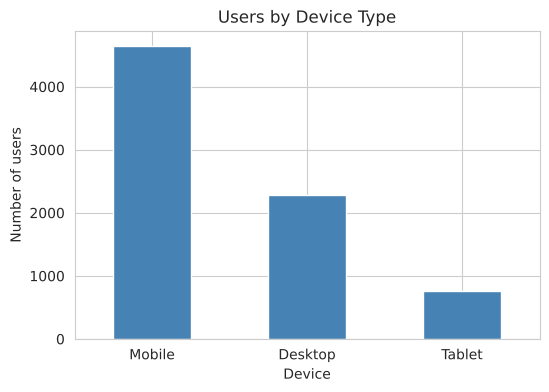

In [32]:
# 2. Users by device type
plt.figure(figsize=(6, 4))
df["device_type"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Users by Device Type")
plt.xlabel("Device")
plt.ylabel("Number of users")
plt.xticks(rotation=0)
plt.show()

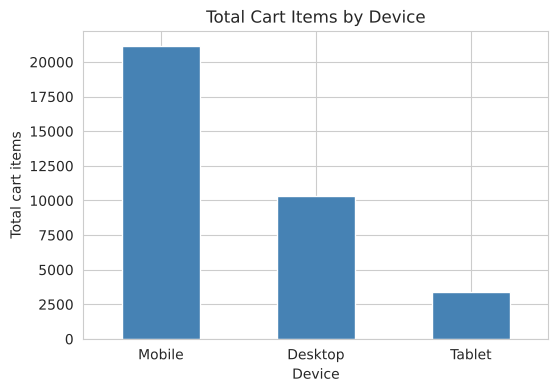

In [33]:
# 3. Total cart items by device
plt.figure(figsize=(6, 4))
df.groupby("device_type")["cart_items"].sum().sort_values(ascending=False).plot(kind="bar", color="steelblue")
plt.title("Total Cart Items by Device")
plt.xlabel("Device")
plt.ylabel("Total cart items")
plt.xticks(rotation=0)
plt.show()

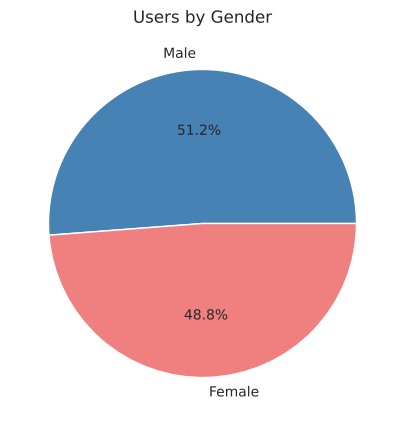

In [34]:
# 4. Gender split (pie chart)
plt.figure(figsize=(5, 5))
df["gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", colors=["steelblue", "lightcoral"])
plt.title("Users by Gender")
plt.ylabel("")
plt.show()

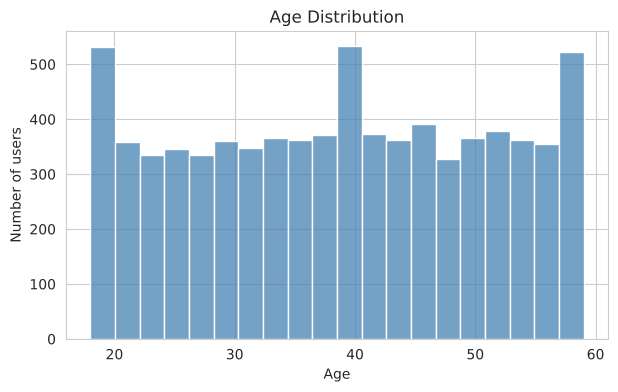

In [35]:
# 5. Age distribution
plt.figure(figsize=(7, 4))
sns.histplot(df["age"], bins=20, color="steelblue")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of users")
plt.show()

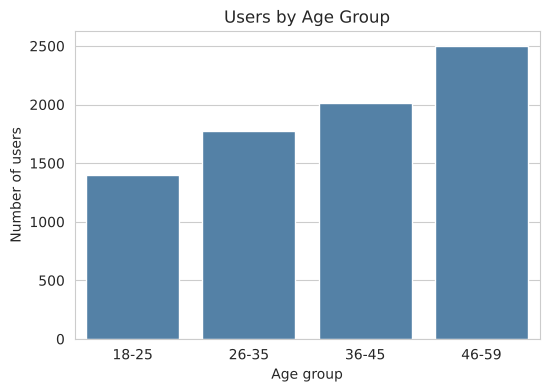

In [36]:
# 6. Users by age group
plt.figure(figsize=(6, 4))
sns.countplot(x="age_group", data=df, color="steelblue")
plt.title("Users by Age Group")
plt.xlabel("Age group")
plt.ylabel("Number of users")
plt.show()

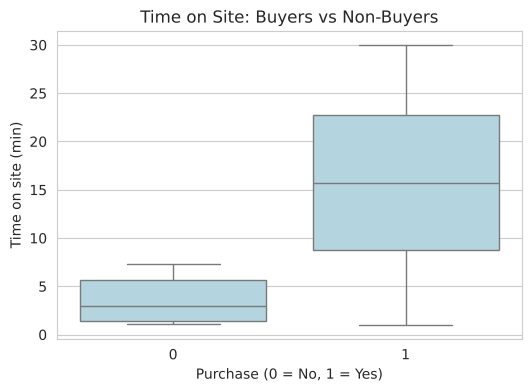

In [37]:
# 7. Time on site - buyers vs non-buyers
plt.figure(figsize=(6, 4))
sns.boxplot(x="purchase", y="time_on_site", data=df, color="lightblue")
plt.title("Time on Site: Buyers vs Non-Buyers")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Time on site (min)")
plt.show()

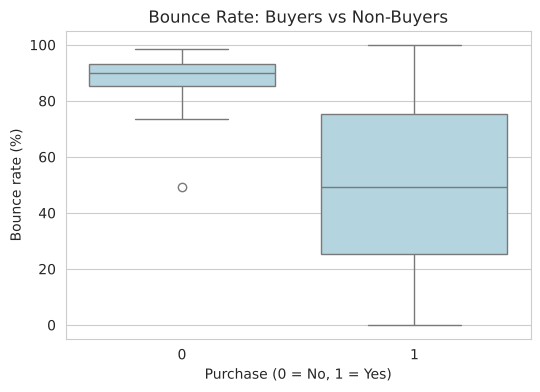

In [38]:
# 8. Bounce rate - buyers vs non-buyers
plt.figure(figsize=(6, 4))
sns.boxplot(x="purchase", y="bounce_rate", data=df, color="lightblue")
plt.title("Bounce Rate: Buyers vs Non-Buyers")
plt.xlabel("Purchase (0 = No, 1 = Yes)")
plt.ylabel("Bounce rate (%)")
plt.show()

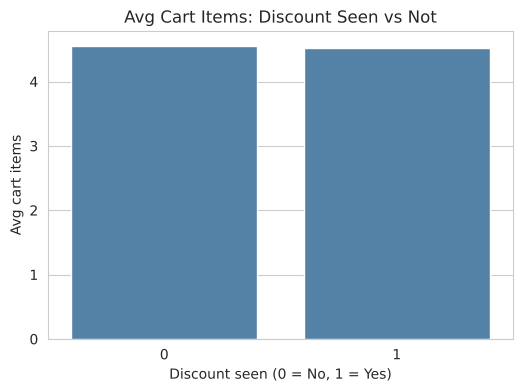

In [39]:
# 9. Average cart items - discount seen vs not
plt.figure(figsize=(6, 4))
sns.barplot(x="discount_seen", y="cart_items", data=df, color="steelblue", errorbar=None)
plt.title("Avg Cart Items: Discount Seen vs Not")
plt.xlabel("Discount seen (0 = No, 1 = Yes)")
plt.ylabel("Avg cart items")
plt.show()

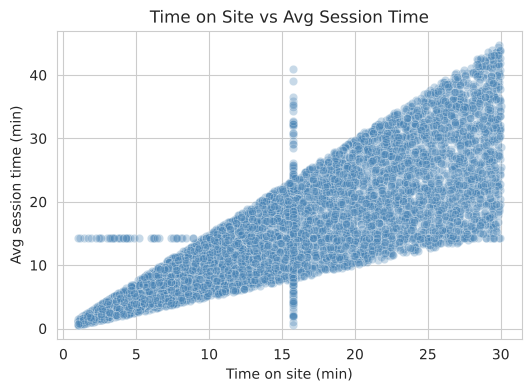

In [40]:
# 10. Time on site vs avg session time
plt.figure(figsize=(6, 4))
sns.scatterplot(x="time_on_site", y="avg_session_time", data=df, alpha=0.3, color="steelblue")
plt.title("Time on Site vs Avg Session Time")
plt.xlabel("Time on site (min)")
plt.ylabel("Avg session time (min)")
plt.show()

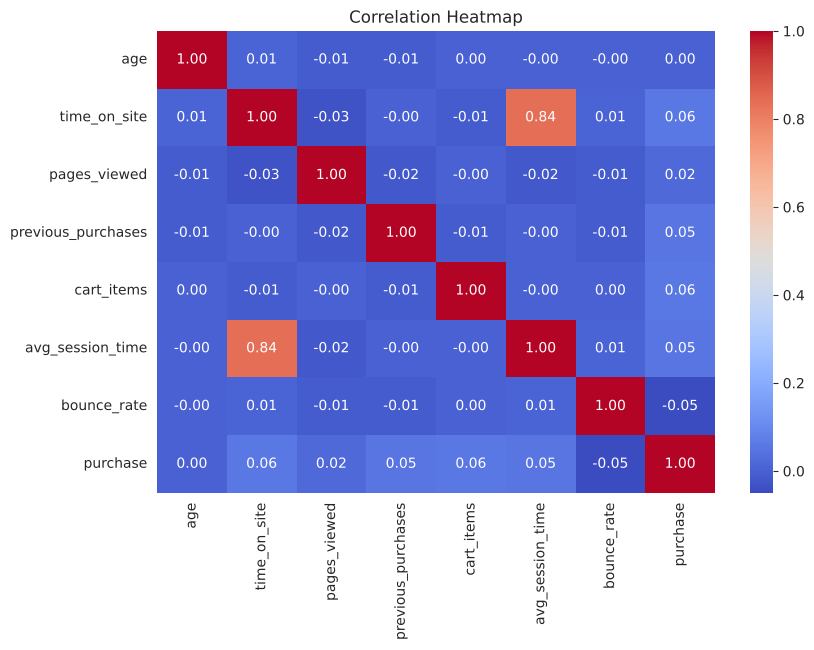

In [41]:
# 11. Correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 7. Business Insights

1. **Very high conversion (≈99.8%).** Only 12 of 7,686 users did not buy. The website turns almost every visit into a sale.
2. **Non-buyers leave fast.** They spend ~3.6 min on site (vs ~15.7 for buyers), add ~0.5 items to cart (vs ~4.5) and have ~86% bounce rate (vs ~50%). **The first few minutes decide the sale.**
3. **Mobile is the main channel.** About 61% of users and ~60% of all cart items come from Mobile, then Desktop (~30%), Tablet (~10%).
4. **Customer groups behave the same.** Male/Female, all age groups and all devices have almost the same cart size (~4.5 items) and past purchases (~7).
5. **Discounts and ads show no lift.** Users who saw a discount or clicked an ad add the same number of items as those who didn't.
6. **46–59 is the largest age group** (2,503 users) and brings the most total cart items (part of this is because it is a wider age band).
7. **time_on_site and avg_session_time are strongly linked (0.85)** – they measure almost the same thing. Other columns have very weak correlation with each other.

### Recommendations
- **Make the mobile experience the top priority** (speed, checkout, app) – it brings most of the business.
- **Fix the first visit:** reduce bounce on landing pages with clear offers and faster load, since non-buyers leave in ~3 minutes.
- **Review discount and ad spend** – no clear sales lift, so test smaller budgets (A/B test) before spending more.
- **Target the 46–59 group** in campaigns since it is the biggest buyer group.
- **Collect order_date, price and revenue** in future – with those we can track monthly sales trend and revenue per user.